In [1]:
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold, cross_val_score, cross_validate, GroupKFold, LeaveOneGroupOut, learning_curve
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.kernel_ridge import KernelRidge
import matplotlib.pyplot as plt
import xgboost as xgb


import yaml
import pandas as pd
import os

Tasks:
1. load global seed for reproducibility
2. load perovskite dataset
3. group dataset by cation pair. (optional) 80/20 tr/ts split useful for later tasks
4. set up HGB model. optionally, XGBoost
5. random CV: train data with HGB (and XGBoost) model, evaluate MAE and stdev (expected MAE ~ 0.074 eV)
6. grouped CV: train data with HGB (and XGBoost) model, evaluate MAE and stdev (expected MAE ~ 0.144 eV)
7. Train HGB (or XGBoost) with two different seeds, check and note whether predictions differ between seeds
8. (need context from here on) Bootstrap data to add variation, confirm non-zero spread
9. ensemble modeling: train data with HGB at five different seeds (grouped and randomCV)
10. check and note whether predictions differ in ensemble (why do ensemble members need to be different?)
11. compare and note MAE and spread between grouped and random CV ensembles

In [2]:
config_path = os.path.join('..', 'configs', 'global_config.yaml')
with open(config_path) as f:
    config = yaml.safe_load(f)

seed = config["seed"]
print(seed)

5


In [3]:
my_df = pd.read_parquet('../parquet/composition_feature_matrix.parquet')

# let's assign a label that groups the alloys by their B1 and B2 site.
# we want to make sure that (B1, B2) of (Ni, Co) is the same as (Co, Ni), so we should sort the pair
my_df['B_pair'] = my_df[['B1','B2']].apply(
    lambda r: '-'.join(sorted([str(r['B1']), str(r['B2'])])), axis=1) # this is a lambda function that applies the sorted labeling

# these are the non-feature columns in the dataframe, which we will drop before training the model
non_feature_cols = ['formula', 'alloy_id', 'A1', 'A2', 'B1', 'B2', 'X', 'is_alloy', 'x_frac', 'Eg', 'dHf', 'dHd', 'B_pair']

In [4]:
# my_df['B_pair'] # uncomment to view B_pair column
# my_df['alloy_id'] # uncomment to view alloy_id column
# my_df.columns[:15] # uncomment to view first 15 columns of the dataframe

In [5]:
# convert the dataframe to a numpy array
X = my_df.drop(columns=non_feature_cols).values

# grab the target columns, Eg and dHd, and convert them to numpy arrays
y_elec = my_df['Eg'].values
y_stab = my_df['dHd'].values
# let's start with band gaps
y = y_elec

In [6]:
# define CV strategies for cross-validation

# random CV
cv_rand = KFold(n_splits = 5, shuffle = True, random_state = seed)

# grouped CV
cv_grouped = GroupKFold(n_splits = 5)

# leave-one-group-out CV
cv_logo = LeaveOneGroupOut()

In [7]:
# # load model
# model_hgb = HistGradientBoostingRegressor(random_state = seed)
# model_xgb = xgb.XGBRegressor(random_state = seed)
# # deprecated, we will use the functions developed below to internally handle model loading

In [8]:
def run_cross_validation(model, X, y, cv, groups=None, random_state=None):
    model_cv = model(random_state=random_state)
    if groups is None:
        result = cross_validate(model_cv, X, y, cv = cv, scoring = 'neg_mean_absolute_error', return_train_score = True)
    else:
        result = cross_validate(model_cv, X, y, cv = cv, groups = groups, scoring = 'neg_mean_absolute_error', return_train_score = True)
    return result

def print_cv_results(cv_results, cv_name=str):
    print(f"{cv_name} CV results:")
    print(f"MAE: {-1 * cv_results['test_score'].mean():.3f} +/- {cv_results['test_score'].std():.3f}")
    print(f"per-fold: {np.round(cv_results['test_score'], 3)}")
    print(f"runtime: {cv_results['fit_time'].sum() + cv_results['score_time'].sum():.2f} s total")

In [9]:
hgb_cv_rand_res = run_cross_validation(HistGradientBoostingRegressor, X, y, cv_rand, random_state = seed)
hgb_cv_grouped_res = run_cross_validation(HistGradientBoostingRegressor, X, y, cv_grouped, groups=my_df['B_pair'],
                                          random_state = seed)

xgb_cv_rand_res = run_cross_validation(xgb.XGBRegressor, X, y, cv_rand, random_state = seed)
xgb_cv_grouped_res = run_cross_validation(xgb.XGBRegressor, X, y, cv_grouped, groups=my_df['B_pair'], random_state = seed)

In [10]:
print('----------------------------------------------')
print('Histogram Gradient Boost Results')
print('----------------------------------------------')
print_cv_results(hgb_cv_rand_res, cv_name="Ungrouped 5-fold, shuffled")
print('----------------------------------------------')
print_cv_results(hgb_cv_grouped_res, cv_name="Grouped 5-fold CV")
print('----------------------------------------------')
print('----------------------------------------------')
print('XGBoost Results')
print('----------------------------------------------')
print_cv_results(xgb_cv_rand_res, cv_name="Ungrouped 5-fold, shuffled")
print('----------------------------------------------')
print_cv_results(xgb_cv_grouped_res, cv_name="Grouped 5-fold CV")
print('----------------------------------------------')

----------------------------------------------
Histogram Gradient Boost Results
----------------------------------------------
Ungrouped 5-fold, shuffled CV results:
MAE: 0.074 +/- 0.004
per-fold: [-0.077 -0.079 -0.074 -0.068 -0.074]
runtime: 9.77 s total
----------------------------------------------
Grouped 5-fold CV CV results:
MAE: 0.154 +/- 0.020
per-fold: [-0.154 -0.16  -0.141 -0.186 -0.127]
runtime: 3.84 s total
----------------------------------------------
----------------------------------------------
XGBoost Results
----------------------------------------------
Ungrouped 5-fold, shuffled CV results:
MAE: 0.070 +/- 0.003
per-fold: [-0.074 -0.073 -0.07  -0.065 -0.069]
runtime: 2.51 s total
----------------------------------------------
Grouped 5-fold CV CV results:
MAE: 0.162 +/- 0.023
per-fold: [-0.165 -0.166 -0.151 -0.199 -0.129]
runtime: 2.02 s total
----------------------------------------------


Here we see XGB and HGB leads to the same results within their fold standard deviation. XGB is about 2x faster for grouped CV and 5x faster for random CV which might come in handy for larger training campaigns.

In [11]:
# check HGB at different seeds
res_dict = {}
num_seeds = 2
for i in range(num_seeds):
    # cv_rand_res = run_cross_validation(HistGradientBoostingRegressor, X, y, cv_rand, random_state = seed+i*100)
    # cv_grouped_res = run_cross_validation(HistGradientBoostingRegressor, X, y, cv_grouped, groups=my_df['B_pair'],
    #                                       random_state = seed+i*100)
    cv_rand_res = run_cross_validation(xgb.XGBRegressor, X, y, cv_rand, random_state = seed+i*100)
    cv_grouped_res = run_cross_validation(xgb.XGBRegressor, X, y, cv_grouped, groups=my_df['B_pair'],
                                          random_state = seed+i*100)
    res_dict[i] = {'rand': cv_rand_res, 'grouped': cv_grouped_res}

for i in range(num_seeds):
    print('----------------------------------------------')
    # print(f'Histogram Gradient Boost Results, seed = {seed+i*100}')
    print(f'XGBoost Results, seed = {seed+i*100}')
    print('----------------------------------------------')
    print_cv_results(res_dict[i]['rand'], cv_name="Ungrouped 5-fold, shuffled")
    print('----------------------------------------------')
    print_cv_results(res_dict[i]['grouped'], cv_name="Grouped 5-fold CV")
    print('----------------------------------------------')

----------------------------------------------
XGBoost Results, seed = 5
----------------------------------------------
Ungrouped 5-fold, shuffled CV results:
MAE: 0.070 +/- 0.003
per-fold: [-0.074 -0.073 -0.07  -0.065 -0.069]
runtime: 1.76 s total
----------------------------------------------
Grouped 5-fold CV CV results:
MAE: 0.162 +/- 0.023
per-fold: [-0.165 -0.166 -0.151 -0.199 -0.129]
runtime: 1.93 s total
----------------------------------------------
----------------------------------------------
XGBoost Results, seed = 105
----------------------------------------------
Ungrouped 5-fold, shuffled CV results:
MAE: 0.070 +/- 0.003
per-fold: [-0.074 -0.073 -0.07  -0.065 -0.069]
runtime: 1.83 s total
----------------------------------------------
Grouped 5-fold CV CV results:
MAE: 0.162 +/- 0.023
per-fold: [-0.165 -0.166 -0.151 -0.199 -0.129]
runtime: 2.28 s total
----------------------------------------------


Here we see that changing the random state seed in our model does not lead different MAEs nor stdev using our dataset. This indicates that variation needs to be introduced into my dataset with other methods for ensemble modeling.

Below, we try bootstrapping our CV folds (bootstrap aggregating, or bagging) to introduce variation.

## Bagging (Bootstrap Aggregating)

in this section, I walk through my thought process for ensemble modeling

Based on my review on ensemble modeling, it aims to evaluate the spread of predicted values that will give us an idea of the model confidence.

The output of ensemble modeling gives us:
1. the mean prediction values we can compare against our targets
2. the stdev of our individual predictions

with bagging, I need to do the below:

In [12]:
# plan for ensemble modeling with bagging

# write function to bootstrap a training set
# apply function n times to each CV split
    # train model on each of the n bootstrapped training sets and predict test set. Record MAE for each prediction
    # ensemble mean = member by member mean of the predictions from each n bootstrapped training sets
    # ensemble stdev (spread) = member by member standard deviation of the predictions from each n bootstrapped training sets
    # both should be vectors of length len(y_test)

# i will need to write a manual loop in this function.
# use cv.split to generate the tr/tst splits (gives the indices)
# use rng = np.random.default_rng(seed) and bootstrap_id = rng.integers(0, len(tr), len(tr))
# set model = HGB(seed) or XGB(seed) and do model.fit(X[tr[bootstrap_id]], y[tr[bootstrap_id]])
# record predictions (model.predict) across each bootstrap, 
# calculate the mean prediction and stdev of each test member across the bootstrap
# store the mean predictions and stdevs of each test member across the bootstrap
# calculate the MAE of the mean_pred-y_tst to get the fold's ensemble MAE and record it
# I should have n_fold number of ensemble MAE values
# and a list of the mean predictions and stdevs (spread) for each member, len(y) long for each

aside: how rng works

In [13]:

# How np.random.default_rng(seed) works. I need to draw rng.integers multiple times from one assignment of np.random to 
# get multiple arrays of random integers.
print('-----')
print('Re-assigning rng = np.random.default_rng(seed) every rng.integers call')
rng = np.random.default_rng(seed)
print(rng.integers(0, 100, 10))
rng = np.random.default_rng(seed)
print(rng.integers(0, 100, 10))
rng = np.random.default_rng(seed)
print(rng.integers(0, 100, 10))

print('-----')
print('Calling rng.integers multiple times from ONE assignment of rng = np.random.default_rng(seed)')
rng = np.random.default_rng(seed)
print(rng.integers(0, 100, 10))
print(rng.integers(0, 100, 10))
print(rng.integers(0, 100, 10))

-----
Re-assigning rng = np.random.default_rng(seed) every rng.integers call
[67 80  2 80 46 51 63 28 97  5]
[67 80  2 80 46 51 63 28 97  5]
[67 80  2 80 46 51 63 28 97  5]
-----
Calling rng.integers multiple times from ONE assignment of rng = np.random.default_rng(seed)
[67 80  2 80 46 51 63 28 97  5]
[27 38 57 40 13  4  0  4 14 99]
[19 65 75 23 28 43 26 97 17 89]


In [26]:
# i will need to write a function with a manual loop.
# use cv.split to generate the tr/tst splits (gives the indices)
# use rng = np.random.default_rng(seed) and bootstrap_id = rng.integers(0, len(tr), len(tr))
# set model = HGB(seed) or XGB(seed) and do model.fit(X[tr[bootstrap_id]], y[tr[bootstrap_id]])
# record predictions (model.predict) across each bootstrap, 
# calculate the mean prediction and stdev of each test member across the bootstrap
# store the mean predictions and stdevs of each test member across the bootstrap
# calculate the MAE of the mean_pred-y_tst to get the fold's ensemble MAE and record it
# I should have n_fold number of ensemble MAE values
# and a list of the mean predictions and stdevs (spread) for each member, len(y) long for each

def bagging_ensemble(model, X, y, cv, n_bootstrap = 5, random_cv = True, groups = None, random_bootstrap = True, random_state = None):
    rng = np.random.default_rng(random_state)
    ensemble_maes = []
    pred_mean = np.zeros(len(y)) # store the mean of the predictions for each member of the target set.
    pred_spread = np.zeros(len(y)) # store the spread of the predictions for each member of the target set.
    if random_cv:
        cv_data = cv.split(X, y)
    else:
        if groups is None:
            raise ValueError('groups cannot be None if random_bootstrap = False')
        cv_data = cv.split(X, y, groups = groups)
    fold_id = np.zeros(len(y), dtype=int)
    fold_i = 1
    for tr_i, tst_i in cv_data:
        X_tr, y_tr = X[tr_i], y[tr_i]
        X_tst, y_tst = X[tst_i], y[tst_i]
        preds_i = []

        if not random_bootstrap:
            if groups is None:
                raise ValueError('groups cannot be None if random_bootstrap = False')
            # group training set to bootstrap across groups
            tr_groups = groups[tr_i] # gets the list of groups in the train set
            unique_groups = np.unique(tr_groups) # gets the set of groups in tr_group. same as set(tr_groups)
        
        for j in range(n_bootstrap):
            if not random_bootstrap:
                if groups is None:
                    raise ValueError('groups cannot be None if random_bootstrap = False')
                # sample groups from the set unique groups
                sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True) 
                # generate indices of members in sampled groups
                bootstrap_id = np.concatenate([np.where(tr_groups == g)[0] for g in sampled_groups])
            else: 
                # sample data by bootstrapping rows (no grouping)
                bootstrap_id = rng.integers(0, len(X_tr), len(X_tr))            
            # print('bootstrap size:', len(bootstrap_id), 'training size:', len(X_tr))            
            X_tr_bootstrap, y_tr_bootstrap = X_tr[bootstrap_id], y_tr[bootstrap_id]
            model_cv = model(random_state = random_state)
            model_cv.fit(X_tr_bootstrap, y_tr_bootstrap)
            bootstrap_preds = model_cv.predict(X_tst)
            preds_i.append(bootstrap_preds)
        preds_i = np.stack(preds_i) # (n_bootstrap x len(y_tst))
        ensemble_mean_i = preds_i.mean(axis=0) # (1 x len(y_tst)) mean of the predictions across each bootstrap iteration
        ensemble_stdev_i = preds_i.std(axis=0, ddof=1) 
        # (1 x len(y_tst)) standard deviation of the predictions across each bootstrap iteration
        # ddof=1: stdev is calculated by dividing N-1 insted of N, a correction of sorts because stdev is usually 
                # underestimated at fewer runs (i.e. n_bootstrap=5 instead of 10000000)
        pred_mean[tst_i] = ensemble_mean_i # store the mean of the predictions for each member of the target set.
        pred_spread[tst_i] = ensemble_stdev_i # store the spread of the predictions for each member of the target set.
        
        fold_ensemble_mae = np.mean(np.abs(ensemble_mean_i - y_tst)) # calculated the fold MAE using the mean of the predictions
        ensemble_maes.append(fold_ensemble_mae)
        fold_id[tst_i] = fold_i
        fold_i += 1
    return ensemble_maes, pred_mean, pred_spread, fold_id

In [27]:
# automate printing for ensemble modeling
def print_ensemble_results(cv_results_tuple, cv_name=str):
    print(f"{cv_name} CV results:")
    print(f"MAE: {(np.mean(cv_results_tuple[0])):.3f} +/- {np.std(cv_results_tuple[0]):.3f}")
    print(f"per-fold: {np.round(cv_results_tuple[0], 3)}")
    print(f"mean ensemble spread: {(np.mean(cv_results_tuple[2])):.3f}")
    # print(f"runtime: {cv_results_tuple['fit_time'].sum() + cv_results_tuple['score_time'].sum():.2f} s total")

In [ ]:
n_bootstraps = 5
XGB_ens_grouped_gbag = bagging_ensemble(model = xgb.XGBRegressor,
                                        X = X, y = y, random_cv = False, cv = cv_grouped, groups = my_df['B_pair'].values,
                                        n_bootstrap = n_bootstraps, random_bootstrap = False, random_state = seed)
XGB_ens_random_gbag = bagging_ensemble(model = xgb.XGBRegressor,
                                       X = X, y = y, random_cv = True, cv = cv_rand, groups = my_df['B_pair'].values,
                                       n_bootstrap = n_bootstraps, random_bootstrap = False, random_state = seed)
XGB_ens_grouped_rbag = bagging_ensemble(model = xgb.XGBRegressor,
                                        X = X, y = y, random_cv = False, cv = cv_grouped, groups = my_df['B_pair'].values,
                                        n_bootstrap = n_bootstraps, random_bootstrap = True, random_state = seed)
XGB_ens_random_rbag = bagging_ensemble(model = xgb.XGBRegressor,
                                       X = X, y = y, random_cv = True, cv = cv_rand, groups = my_df['B_pair'].values,
                                       n_bootstrap = n_bootstraps, random_bootstrap = True, random_state = seed)

# XGB is faster than HGB and results in virtually the same results
# HGB_ens_grouped_gbag = bagging_ensemble(model = HistGradientBoostingRegressor,
#                                         X = X, y = y, random_cv = False, cv = cv_grouped, groups = my_df['B_pair'].values,
#                                         n_bootstrap = n_bootstraps, random_bootstrap = False, random_state = seed)
# HGB_ens_random_gbag = bagging_ensemble(model = HistGradientBoostingRegressor,
#                                        X = X, y = y, random_cv = True, cv = cv_rand, groups = my_df['B_pair'].values,
#                                        n_bootstrap = n_bootstraps, random_bootstrap = False, random_state = seed)
# HGB_ens_grouped_rbag = bagging_ensemble(model = HistGradientBoostingRegressor,
#                                         X = X, y = y, random_cv = False, cv = cv_grouped, groups = my_df['B_pair'].values,
#                                         n_bootstrap = n_bootstraps, random_bootstrap = True, random_state = seed)
# HGB_ens_random_rbag = bagging_ensemble(model = HistGradientBoostingRegressor,
#                                        X = X, y = y, random_cv = True, cv = cv_rand, groups = my_df['B_pair'].values,
#                                        n_bootstrap = n_bootstraps, random_bootstrap = True, random_state = seed)

In [ ]:
# save results to a dataframe

#ensemble_maes, pred_mean, pred_spread

XGB_ens_grouped_gbag_dict = {k:XGB_ens_grouped_gbag[i+1] for i, k in enumerate(['gcv_gbag_pred', 'gcv_gbag_spread', 'gcv_gbag_fold'])}
XGB_ens_random_gbag_dict = {k:XGB_ens_random_gbag[i+1] for i, k in enumerate(['rcv_gbag_pred', 'rcv_gbag_spread', 'rcv_gbag_fold'])}
XGB_ens_grouped_rbag_dict = {k:XGB_ens_grouped_rbag[i+1] for i, k in enumerate(['gcv_rbag_pred', 'gcv_rbag_spread', 'gcv_rbag_fold'])}
XGB_ens_random_rbag_dict = {k:XGB_ens_random_rbag[i+1] for i, k in enumerate(['rcv_rbag_pred', 'rcv_rbag_spread', 'rcv_rbag_fold'])}

results_dict = {'formula': my_df['formula'], 'B_pair': my_df['B_pair'], 'Eg_true': y}
results_dict.update(XGB_ens_grouped_gbag_dict)
results_dict.update(XGB_ens_random_gbag_dict)
results_dict.update(XGB_ens_grouped_rbag_dict)
results_dict.update(XGB_ens_random_rbag_dict)
# print(results_dict.keys())

results_df = pd.DataFrame(results_dict)
results_df.to_csv('XGB_ensemble_pred_spread.csv')

# HGB_ens_grouped_gbag_dict = {k:HGB_ens_grouped_gbag[i+1] for i, k in enumerate(['gcv_gbag_pred', 'gcv_gbag_spread', 'gcv_gbag_fold'])}
# HGB_ens_random_gbag_dict = {k:HGB_ens_random_gbag[i+1] for i, k in enumerate(['rcv_gbag_pred', 'rcv_gbag_spread', 'rcv_gbag_fold'])}
# HGB_ens_grouped_rbag_dict = {k:HGB_ens_grouped_rbag[i+1] for i, k in enumerate(['gcv_rbag_pred', 'gcv_rbag_spread', 'gcv_rbag_fold'])}
# HGB_ens_random_rbag_dict = {k:HGB_ens_random_rbag[i+1] for i, k in enumerate(['rcv_rbag_pred', 'rcv_rbag_spread', 'rcv_rbag_fold'])}

In [19]:
print('----------------------------------------------')
print('Grouped bagging')
print('----------------------------------------------')
print('----------------------------------------------')
print('Histogram Gradient Boost Results')
print('----------------------------------------------')
print_ensemble_results(HGB_ens_random_gbag, cv_name='Ungrouped 5-fold, shuffled, ' + str(n_bootstraps) + ' bootstraps')
print('----------------------------------------------')
print_ensemble_results(HGB_ens_grouped_gbag, cv_name='Grouped 5-fold CV, ' + str(n_bootstraps) + ' bootstraps')
print('----------------------------------------------')
print('----------------------------------------------')
print('XGBoost Results')
print('----------------------------------------------')
print_ensemble_results(XGB_ens_random_gbag, cv_name='Ungrouped 5-fold, shuffled, ' + str(n_bootstraps) + ' bootstraps')
print('----------------------------------------------')
print_ensemble_results(XGB_ens_grouped_gbag, cv_name='Grouped 5-fold CV' + str(n_bootstraps) + ' bootstraps')
print('----------------------------------------------')

----------------------------------------------
Grouped bagging
----------------------------------------------
----------------------------------------------
Histogram Gradient Boost Results
----------------------------------------------
Ungrouped 5-fold, shuffled, 5 bootstraps CV results:
MAE: 0.096 +/- 0.004
per-fold: [0.096 0.103 0.092 0.093 0.096]
mean ensemble spread: 0.089
----------------------------------------------
Grouped 5-fold CV, 5 bootstraps CV results:
MAE: 0.174 +/- 0.022
per-fold: [0.171 0.183 0.146 0.209 0.16 ]
mean ensemble spread: 0.135
----------------------------------------------
----------------------------------------------
XGBoost Results
----------------------------------------------
Ungrouped 5-fold, shuffled, 5 bootstraps CV results:
MAE: 0.092 +/- 0.005
per-fold: [0.092 0.102 0.088 0.088 0.093]
mean ensemble spread: 0.100
----------------------------------------------
Grouped 5-fold CV5 bootstraps CV results:
MAE: 0.184 +/- 0.022
per-fold: [0.173 0.199 0.1

In [20]:
print('----------------------------------------------')
print('Random bagging')
print('----------------------------------------------')
print('----------------------------------------------')
print('Histogram Gradient Boost Results')
print('----------------------------------------------')
print_ensemble_results(HGB_ens_random_rbag, cv_name='Ungrouped 5-fold, shuffled, ' + str(n_bootstraps) + ' bootstraps')
print('----------------------------------------------')
print_ensemble_results(HGB_ens_grouped_rbag, cv_name='Grouped 5-fold CV, ' + str(n_bootstraps) + ' bootstraps')
print('----------------------------------------------')
print('----------------------------------------------')
print('XGBoost Results')
print('----------------------------------------------')
print_ensemble_results(XGB_ens_random_rbag, cv_name='Ungrouped 5-fold, shuffled, ' + str(n_bootstraps) + ' bootstraps')
print('----------------------------------------------')
print_ensemble_results(XGB_ens_grouped_rbag, cv_name='Grouped 5-fold CV' + str(n_bootstraps) + ' bootstraps')
print('----------------------------------------------')

----------------------------------------------
Random bagging
----------------------------------------------
----------------------------------------------
Histogram Gradient Boost Results
----------------------------------------------
Ungrouped 5-fold, shuffled, 5 bootstraps CV results:
MAE: 0.076 +/- 0.003
per-fold: [0.079 0.081 0.076 0.071 0.076]
mean ensemble spread: 0.039
----------------------------------------------
Grouped 5-fold CV, 5 bootstraps CV results:
MAE: 0.154 +/- 0.017
per-fold: [0.152 0.161 0.142 0.182 0.131]
mean ensemble spread: 0.051
----------------------------------------------
----------------------------------------------
XGBoost Results
----------------------------------------------
Ungrouped 5-fold, shuffled, 5 bootstraps CV results:
MAE: 0.069 +/- 0.004
per-fold: [0.072 0.074 0.068 0.063 0.066]
mean ensemble spread: 0.052
----------------------------------------------
Grouped 5-fold CV5 bootstraps CV results:
MAE: 0.157 +/- 0.019
per-fold: [0.154 0.163 0.14

In [21]:
from scipy.stats import spearmanr

HGB ens grouped
Spearman rho = 0.56


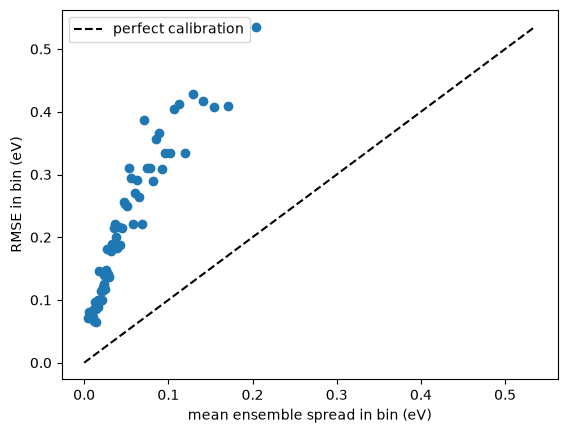

XGB ens grouped
Spearman rho = 0.51


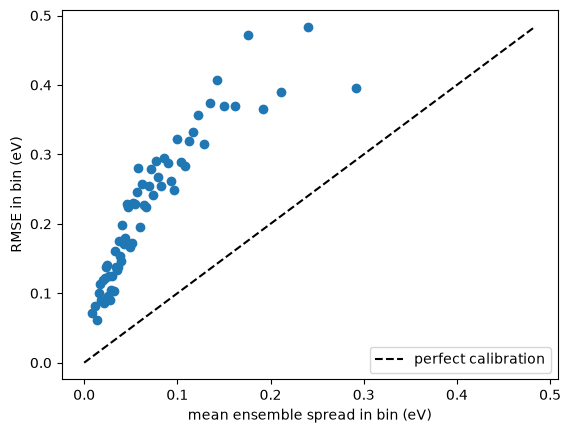

HGB ens random
Spearman rho = 0.56


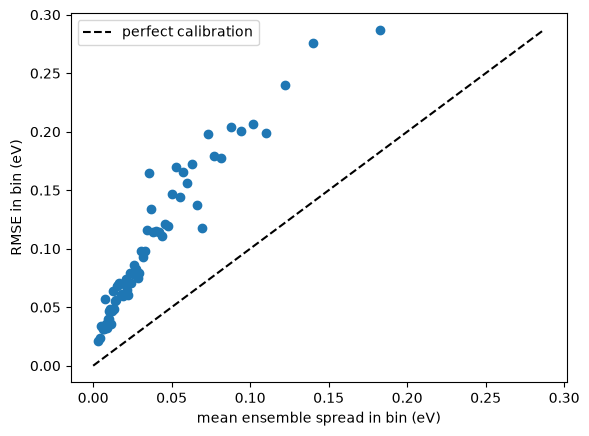

XGB ens random
Spearman rho = 0.54


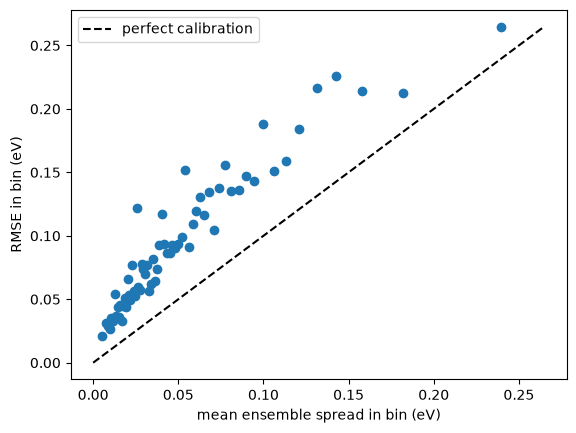

In [25]:


bs_list = [HGB_ens_grouped_gbag, XGB_ens_grouped_gbag, HGB_ens_random_gbag, XGB_ens_random_gbag]
bs_list = [HGB_ens_grouped_rbag, XGB_ens_grouped_rbag, HGB_ens_random_rbag, XGB_ens_random_rbag]
bs_name = ['HGB ens grouped', 'XGB ens grouped', 'HGB ens random', 'XGB ens random']

n_bins = 65 # ~100x smaller than number of data, so about 100 points per bin

for i, res_tuple in enumerate(bs_list):
    name = bs_name[i]
    print(name)
    pred_mean = res_tuple[1]
    pred_spread = res_tuple[2]
    abs_err = np.abs(pred_mean-y)
    rho, p = spearmanr(pred_spread, abs_err)
    print(f'Spearman rho = {rho:.2f}')

    # returns an array of indices that, when used to index the original array, will produce a sorted version of that array.
    order = np.argsort(pred_spread)
    # splits the array of indices into n_bins number of groups
    sorted_bins = np.array_split(order, n_bins)
    # sorted_bins = order

    # here we generate the binned spread and rmse values, in increasing spread values (bins)
    bin_spread = [pred_spread[b].mean() for b in sorted_bins]
    bin_rmse = [np.sqrt(np.mean((pred_mean[b]-y[b])**2)) for b in sorted_bins]
    
    # plt.scatter(bin_spread, bin_rmse, 'o-')
    plt.plot(bin_spread, bin_rmse, 'o')
    lim = max(max(bin_spread), max(bin_rmse))
    plt.plot([0, lim], [0,lim], 'k--', label='perfect calibration')
    plt.xlabel('mean ensemble spread in bin (eV)')
    plt.ylabel('RMSE in bin (eV)')
    plt.legend()
    plt.show()